In [ ]:
# from google.colab import drive

# drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
def clean():
    import gc
    import torch

    # Release cached GPU memory
    gc.collect()
    torch.cuda.empty_cache()

clean()

In [5]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Program using device: {device}")

Program using device: cuda


In [6]:
!nvidia-smi

Sun Nov 15 22:09:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 596.36                 Driver Version: 596.36         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX 3500 Ada Gene...  WDDM  |   00000000:01:00.0  On |                  Off |
| N/A   66C    P3            115W /   94W |   11673MiB /  12282MiB |     79%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

For Google Colab only

In [ ]:
# from pathlib import Path

# datapath_zip = Path("/content/drive/MyDrive/COLAB/A2/data.zip")

In [6]:
# from pathlib import Path

# datapath_zip = Path("/content/drive/MyDrive/COLAB/A2/data/data_yolo.zip")

# !unzip -q "/content/drive/MyDrive/COLAB/A2/data/data_yolo.zip" -d "/content/drive/MyDrive/COLAB/A2/data"

In [ ]:
# !unzip -q "/content/drive/MyDrive/COLAB/A2/data.zip" -d "/content/drive/MyDrive/COLAB/A2/"

In [ ]:
# from pathlib import Path
# ROOT = Path("/content/drive/MyDrive/COLAB/A2/data/VOCdevkit")
# OUTPUT = Path("/content/drive/MyDrive/COLAB/A2/data")

In [ ]:
# import shutil
# import xml.etree.ElementTree as ET

# CLASSES = [
#     "aeroplane", "bicycle", "bird", "boat", "bottle",
#     "bus", "car", "cat", "chair", "cow",
#     "diningtable", "dog", "horse", "motorbike", "person",
#     "pottedplant", "sheep", "sofa", "train", "tvmonitor"
# ]

# CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASSES)}

# SOURCES = {
#     "train": (
#         ROOT / "VOC2012/Annotations",
#         ROOT / "VOC2012/JPEGImages"
#     ),
#     "val": (
#         ROOT / "VOC2007/Annotations/val",
#         ROOT / "VOC2007/JPEGImages/val"
#     ),
#     "test": (
#         ROOT / "VOC2007/Annotations/test",
#         ROOT / "VOC2007/JPEGImages/test"
#     )
# }

# def convert_box(box, img_width, img_height):

#     xmin = float(box.findtext("xmin"))
#     ymin = float(box.findtext("ymin"))
#     xmax = float(box.findtext("xmax"))
#     ymax = float(box.findtext("ymax"))

#     xmin = max(0, min(xmin, img_width))
#     xmax = max(0, min(xmax, img_width))
#     ymin = max(0, min(ymin, img_height))
#     ymax = max(0, min(ymax, img_height))

#     if xmax <= xmin or ymax <= ymin:
#         return None

#     x_center = ((xmin + xmax) / 2) / img_width
#     y_center = ((ymin + ymax) / 2) / img_height
#     width = (xmax - xmin) / img_width
#     height = (ymax - ymin) / img_height

#     return x_center, y_center, width, height

# # split to YOLO format folder
# def process_split(split, annotation_dir, image_dir):
#     output_images = OUTPUT / "images" / split
#     output_labels = OUTPUT / "labels" / split
#     output_images.mkdir(parents=True, exist_ok=True)
#     output_labels.mkdir(parents=True, exist_ok=True)
#     image_count = 0
#     box_count = 0
#     missing_images = []
#     invalid_boxes = 0
#     unknown_classes = set()
#     xml_files = sorted(annotation_dir.glob("*.xml"))

#     for xml_file in xml_files:
#         annotation = ET.parse(xml_file).getroot()
#         filename = annotation.findtext("filename")
#         if not filename:
#             filename = xml_file.stem + ".jpg"
#         image_path = image_dir / filename

#         # Check image exists in source or previous output
#         destination_image = output_images / filename

#         if image_path.exists():
#             source_image = image_path
#         elif destination_image.exists():
#             source_image = destination_image
#         else:
#             missing_images.append(filename)
#             continue

#         size = annotation.find("size")
#         img_width = int(size.findtext("width"))
#         img_height = int(size.findtext("height"))

#         if img_width <= 0 or img_height <= 0:
#             continue

#         yolo_labels = []
#         for obj in annotation.findall("object"):
#             class_name = obj.findtext("name")
#             if class_name not in CLASS_TO_ID:
#                 unknown_classes.add(class_name)
#                 continue

#             box = obj.find("bndbox")
#             converted = convert_box(
#                 box,
#                 img_width,
#                 img_height
#             )
#             if converted is None:
#                 invalid_boxes += 1
#                 continue

#             class_id = CLASS_TO_ID[class_name]
#             x_center, y_center, width, height = converted
#             yolo_labels.append(
#                 f"{class_id} "
#                 f"{x_center:.6f} "
#                 f"{y_center:.6f} "
#                 f"{width:.6f} "
#                 f"{height:.6f}"
#             )
#             box_count += 1

#         # Save YOLO label
#         label_path = output_labels / f"{xml_file.stem}.txt"
#         label_path.write_text(
#             "\n".join(yolo_labels),
#             encoding="utf-8"
#         )

#         # Move image, not copy
#         if source_image != destination_image:
#             if destination_image.exists():
#                 raise FileExistsError(
#                     f"Destination already exists: {destination_image}"
#                 )
#             shutil.move(
#                 str(source_image),
#                 str(destination_image)
#             )
#         image_count += 1

#     print(f"\n===== {split.upper()} =====")
#     print("Images:", image_count)
#     print("Labels:", image_count)
#     print("Bounding boxes:", box_count)
#     print("Missing images:", len(missing_images))
#     print("Invalid boxes:", invalid_boxes)
#     print("Unknown classes:", unknown_classes)

#     if missing_images:
#         print("Missing examples:", missing_images[:5])

# for split, (annotation_dir, image_dir) in SOURCES.items():
#     if not annotation_dir.exists():
#         raise FileNotFoundError(annotation_dir)
#     if not image_dir.exists() and not (
#         OUTPUT / "images" / split
#     ).exists():
#         raise FileNotFoundError(image_dir)
#     process_split(
#         split,
#         annotation_dir,
#         image_dir
#     )

# # create yaml in local colab
# yaml_content = f"""path: {OUTPUT.resolve().as_posix()}
# train: images/train
# val: images/val
# test: images/test
# nc: {len(CLASSES)}
# names: {CLASSES}
# """

# (OUTPUT / "data.yaml").write_text(
#     yaml_content,
#     encoding="utf-8"
# )

In [8]:
from pathlib import Path

OUTPUT = Path("../data_yolo").resolve()
print("\n========== YOLO DATASET SUMMARY ==========")
for split in ["train", "val", "test"]:
    image_dir = OUTPUT / "images" / split
    label_dir = OUTPUT / "labels" / split
    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))
    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
print("\nDataset YAML:", OUTPUT / "data.yaml")


========== YOLO DATASET SUMMARY ==========

TRAIN
Images: 17125
Labels: 17125

VAL
Images: 2459
Labels: 2459

TEST
Images: 2493
Labels: 2493

Dataset YAML: C:\workspace\04_LEARNING\miniproject\CO5085_261_BTL_A1_PhungBichLan\BTL_A2\data_yolo\data.yaml


In [ ]:
# from pathlib import Path
# data_path = Path("/content/drive/MyDrive/COLAB/A2/data").resolve()

In [9]:
from pathlib import Path
data_path = Path("../data_yolo").resolve()

In [10]:
data_path_train_img = data_path / "images" / "train"
data_path_train_anno = data_path / "labels" / "train"
data_path_val_img = data_path / "images" / "val"
data_path_val_anno = data_path / "labels" / "val"
data_path_test_img = data_path / "images" / "test"
data_path_test_anno = data_path / "labels" / "test"

In [11]:
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

def count_classes(anno_dir):
    class_counts = Counter()
    if not Path(anno_dir).exists():
        return class_counts

    for txt_file in Path(anno_dir).glob("*.txt"):
        try:
            with open(txt_file, "r") as f:
                lines = f.readlines()
        except Exception:
            continue

        for line in lines:
            cls = line.split()[0]
            class_counts[cls] += 1

    return class_counts


train_counts = count_classes(data_path_train_anno)
test_counts = count_classes(data_path_test_anno)
val_counts = count_classes(data_path_val_anno)

 Class  Train  Test  Val  Train (%)  Test (%)  Val (%)
     0   1002   174  137       2.50      2.28     1.86
     1    837   194  195       2.09      2.54     2.65
     2   1271   338  238       3.17      4.43     3.24
     3   1059   206  187       2.64      2.70     2.54
     4   1561   342  315       3.89      4.49     4.28
     5    685   127  127       1.71      1.67     1.73
     6   2492   768  773       6.21     10.07    10.51
     7   1277   188  182       3.18      2.47     2.48
     8   3056   731  643       7.61      9.59     8.75
     9    771   144  185       1.92      1.89     2.52
    10    800   151  148       1.99      1.98     2.01
    11   1598   270  260       3.98      3.54     3.54
    12    803   195  200       2.00      2.56     2.72
    13    801   202  167       2.00      2.65     2.27
    14  17401  2590 2637      43.35     33.97    35.87
    15   1202   303  289       2.99      3.97     3.93
    16   1084   164  147       2.70      2.15     2.00
    17    

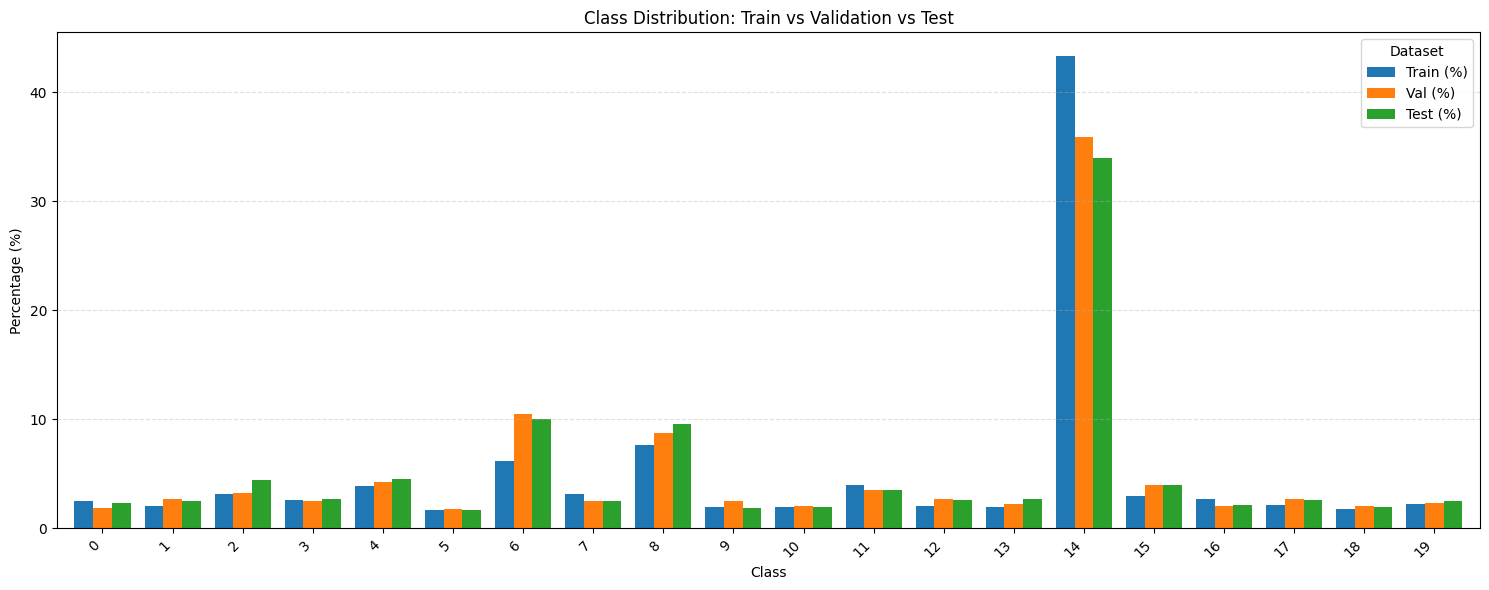

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

classes = sorted(set(train_counts) | set(test_counts) | set(val_counts))

df = pd.DataFrame({
    "Class": classes,
    "Train": [train_counts[c] for c in classes],
    "Test": [test_counts[c] for c in classes],
    "Val": [val_counts[c] for c in classes]
})

df["Class"] = df["Class"].astype(int)
df = df.sort_values("Class").reset_index(drop=True)

df["Train (%)"] = df["Train"] / df["Train"].sum() * 100
df["Test (%)"] = df["Test"] / df["Test"].sum() * 100
df["Val (%)"] = df["Val"] / df["Val"].sum() * 100

print(df.round(2).to_string(index=False))

df.plot(
    x="Class",
    y=["Train (%)", "Val (%)", "Test (%)"],
    kind="bar",
    figsize=(15, 6),
    width=0.8
)

plt.title("Class Distribution: Train vs Validation vs Test")
plt.xlabel("Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Colab only, define to move data from personal drive to local colab

In [ ]:
# from pathlib import Path

# # Original dataset on Google Drive (NEVER MODIFY)
# DRIVE_DATA_DIR = Path("/content/drive/MyDrive/COLAB/A2/data")

# # Temporary local dataset in Colab
# LOCAL_DATA_DIR = Path("/content/data")

In [13]:
LOCAL_DATA_DIR = Path("../data_yolo")

In [51]:
DATA_YAML = LOCAL_DATA_DIR / "data.yaml"
MODEL_NAME = "yolo11n.pt"
EPOCHS = 50
BATCH_SIZE = 4
IMG_SIZE = 640
OPTIMIZER = "SGD"
LR0 = 0.001
LRF = 0.01
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
WORKERS = 0
PATIENCE = 20
FREEZE = None
SEED = 42
DETERMINISTIC = True
PROJECT = "C:/content/drive/MyDrive/COLAB/A2/runs"
EXPERIMENT_NAME = "yolo11n_full_finetune"

Google colab only, copy to local colab for more speedup training time

In [ ]:
# import shutil
# from pathlib import Path

# # =====================================================
# # CONFIGURATION
# # =====================================================

# DRIVE_DATA_DIR = Path(
#     "/content/drive/MyDrive/COLAB/A2/data"
# )

# LOCAL_DATA_DIR = Path("/content/data")

# # =====================================================
# # COPY IMAGES AND LABELS
# # =====================================================

# for folder in ["images", "labels"]:

#     source = DRIVE_DATA_DIR / folder
#     destination = LOCAL_DATA_DIR / folder

#     if not source.exists():
#         raise FileNotFoundError(source)

#     # Remove old local folder only
#     if destination.exists():
#         shutil.rmtree(destination)

#     # Copy folder
#     shutil.copytree(source, destination)

#     print(f"Copied: {folder}")

# print("\nDataset copied successfully!")

Copied: images
Copied: labels

Dataset copied successfully!


In [ ]:
# # =====================================================
# # UPDATE LOCAL DATA YAML
# # =====================================================

# data_config = {
#     "path": str(LOCAL_DATA_DIR),
#     "train": "images/train",
#     "val": "images/val",
#     "test": "images/test",
#     "nc": 20,
#     "names": [
#         "aeroplane", "bicycle", "bird", "boat", "bottle",
#         "bus", "car", "cat", "chair", "cow",
#         "diningtable", "dog", "horse", "motorbike", "person",
#         "pottedplant", "sheep", "sofa", "train", "tvmonitor"
#     ]
# }

# with open(DATA_YAML, "w") as f:
#     yaml.safe_dump(data_config, f, sort_keys=False)

# print(DATA_YAML.read_text())

path: /content/data
train: images/train
val: images/val
test: images/test
nc: 20
names:
- aeroplane
- bicycle
- bird
- boat
- bottle
- bus
- car
- cat
- chair
- cow
- diningtable
- dog
- horse
- motorbike
- person
- pottedplant
- sheep
- sofa
- train
- tvmonitor



In [23]:
def validate_dataset():
    for split in ["train", "val", "test"]:
        image_dir = LOCAL_DATA_DIR / "images" / split
        label_dir = LOCAL_DATA_DIR / "labels" / split
        if not image_dir.exists() or not label_dir.exists():
            raise FileNotFoundError(f"Missing dataset directory: {split}")

        images = list(image_dir.glob("*"))
        labels = list(label_dir.glob("*.txt"))
        print(f"{split.upper():5s} | " f"Images: {len(images):6d} | " f"Labels: {len(labels):6d}")

        if not images:
            raise ValueError(f"No images found in {split}")

        if not labels:
            raise ValueError(f"No labels found in {split}")

validate_dataset()

TRAIN | Images:  17125 | Labels:  17125
VAL   | Images:   2459 | Labels:   2459
TEST  | Images:   2493 | Labels:   2493


In [24]:
import cv2

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

def draw_bbox_on_image(image, label_path):
    h, w = image.shape[:2]
    if not label_path.exists():
        return image

    with open(label_path, "r") as f:
        for line in f:
            class_id, xc, yc, bw, bh = map(float, line.split())

            # YOLO normalized xywh -> pixel xyxy
            xc *= w
            yc *= h
            bw *= w
            bh *= h

            xmin = int(xc - bw / 2)
            ymin = int(yc - bh / 2)
            xmax = int(xc + bw / 2)
            ymax = int(yc + bh / 2)

            class_id = int(class_id)
            class_name = VOC_CLASSES[class_id]
            cv2.rectangle(image, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
            
            text_y = max(ymin - 30, 20)
            cv2.rectangle(image, (xmin, text_y - 20), (xmin + 120, text_y + 5), (0, 255, 0), -1)
            cv2.putText(image, class_name, (xmin + 2, text_y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

            # Annotation: class name + bounding box
            annotation = (f"{class_name} " f"({xmin}, {ymin}, {xmax}, {ymax})")
            text_y = max(ymin - 10, 20)
            cv2.putText(image, annotation, (xmin, text_y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    return image

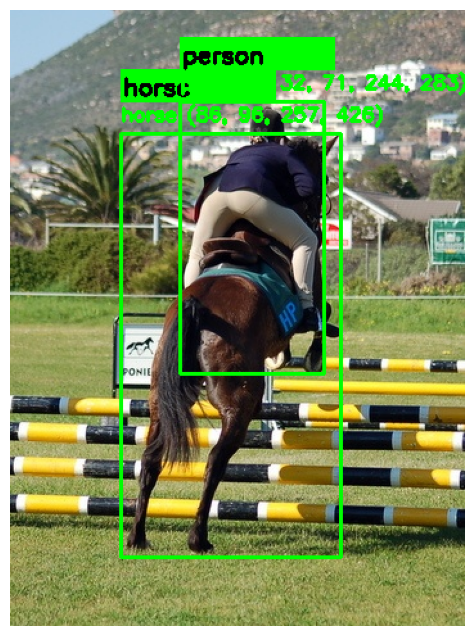

In [39]:
image_dir = OUTPUT / "images" / "test"
image_path = next(image_dir.glob("*.jpg"))
label_path = label_dir / f"{image_path.stem}.txt"

image = cv2.imread(str(image_path))
image_drawn = draw_bbox_on_image(image.copy(), label_path)

image_drawn = cv2.cvtColor(image_drawn, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image_drawn)
plt.axis("off")
plt.show()

In [ ]:
# # Start from epoch 0

# from ultralytics import YOLO

# # Load YOLO model
# model_yolo = YOLO("yolo11n.pt")

# # Display detailed architecture
# print(model_yolo.model)

# # Display model summary
# model_yolo.info(verbose=True)

# # Display each layer separately
# for i, layer in enumerate(model_yolo.model.model):
#     params = sum(p.numel() for p in layer.parameters())
#     trainable = sum(
#         p.numel()
#         for p in layer.parameters()
#         if p.requires_grad
#     )

#     print(f"\nLayer {i}: {layer.__class__.__name__}")
#     print(layer)
#     print(f"Parameters: {params:,}")
#     print(f"Trainable Parameters: {trainable:,}")

In [26]:
history_yolo11n = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],

    # Training time
    "epoch_time": [],

    # Learning rate
    "lr_bb": [],
    "lr_head": [],

    # Individual training losses
    "train_loss_objectness": [],
    "train_loss_rpn_box_reg": [],
    "train_loss_classifier": [],
    "train_loss_box_reg": [],

    # Validation metrics
    "val_map": [],
    "val_map_50": [],
    "val_map_75": []
}

result_yolo11n = {
    # Test metrics
    "test_loss": 0.0,
    "test_map": 0.0,
    "test_map_50": 0.0,
    "test_map_75": 0.0,

    # Detection metrics
    "precision": 0.0,
    "recall": 0.0,
    "f1_score": 0.0,

    # Performance
    "train_time": 0.0,
    "test_time": 0.0,
    "inference_time_per_image": 0.0,

    # Model complexity
    "total_params": 0,
    "trainable_params": 0,

    # Best training results
    "min_train_loss": 0.0,
    "min_val_loss": 0.0,
    "max_val_map": 0.0,
    "max_val_map_50": 0.0,
    "max_val_map_75": 0.0,

    # Best epoch
    "best_epoch": 0
}

In [52]:
from ultralytics import YOLO

def train_yolo(model=MODEL_NAME, resume=False):
    model = YOLO(model)
    if resume:
        results = model.train(
            resume=True,
            data=str(DATA_YAML),
            project=PROJECT,
            name=EXPERIMENT_NAME)
    else:
        results = model.train(
            data=str(DATA_YAML),
            epochs=EPOCHS,
            batch=BATCH_SIZE,
            imgsz=IMG_SIZE,
            optimizer=OPTIMIZER,
            lr0=LR0,
            lrf=LRF,
            momentum=MOMENTUM,
            weight_decay=WEIGHT_DECAY,
            cos_lr=False,
            pretrained=True,
            freeze=FREEZE,
            seed=SEED,
            deterministic=DETERMINISTIC,
            workers=WORKERS,
            patience=PATIENCE,
            save=True,
            plots=True,
            verbose=True,
            project=PROJECT,
            name=EXPERIMENT_NAME,
            exist_ok=True
        )
    return model, results

In [ ]:
# model_yolo, results_yolo = train_yolo()

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=yolo11n_full_finetune, nbs=64, nms=None, opset=None, optimize=False,

In [ ]:
# LAST_MODEL_PATH = ("/content/drive/MyDrive/COLAB/A2/runs/yolo11n_full_finetune/weights/last.pt")

# model = YOLO(str(LAST_MODEL_PATH))

# checkpoint = model.ckpt

# last_epoch = checkpoint["epoch"]
# total_epochs = checkpoint["train_args"]["epochs"]

# print("Checkpoint:", LAST_MODEL_PATH)
# print("Completed epoch:", last_epoch + 1)
# print("Total configured epochs:", total_epochs)
# print("Remaining epochs:", max(0, total_epochs - (last_epoch + 1)))

Checkpoint: /content/drive/MyDrive/COLAB/A2/runs/yolo11n_full_finetune/weights/last.pt
Completed epoch: 12
Total configured epochs: 50
Remaining epochs: 38


In [53]:
from pathlib import Path

LAST_MODEL_PATH = Path("C:/content/drive/MyDrive/COLAB/A2/runs/yolo11n_full_finetune/weights/last.pt")

model = YOLO(str(LAST_MODEL_PATH))

checkpoint = model.ckpt

last_epoch = checkpoint["epoch"]
total_epochs = checkpoint["train_args"]["epochs"]

print("Checkpoint:", LAST_MODEL_PATH)
print("Completed epoch:", last_epoch + 1)
print("Total configured epochs:", total_epochs)
print("Remaining epochs:", max(0, total_epochs - (last_epoch + 1)))

Checkpoint: C:\content\drive\MyDrive\COLAB\A2\runs\yolo11n_full_finetune\weights\last.pt
Completed epoch: 44
Total configured epochs: 50
Remaining epochs: 6


In [54]:
model_yolo, results_yolo = train_yolo(LAST_MODEL_PATH, resume=True)

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
WARNING Resume ignores ['project'], using checkpoint values. Start a new run to change them.
Ultralytics 8.4.213  Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=..\data_yolo\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0

In [81]:
# =====================================================
# TEST EVALUATION
# =====================================================

BEST_MODEL_PATH = (
    Path(PROJECT)
    / EXPERIMENT_NAME
    / "weights"
    / "best.pt"
)

best_model = YOLO(str(BEST_MODEL_PATH))

test_results = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    plots=True
)

print(f"Test Precision: {test_results.box.mp:.4f} ({test_results.box.mp * 100:.2f}%)")
print(f"Test Recall: {test_results.box.mr:.4f} ({test_results.box.mr * 100:.2f}%)")
print(f"Test mAP50: {test_results.box.map50:.4f}")
print(f"Test mAP50-95: {test_results.box.map:.4f}")

Ultralytics 8.4.213  Python-3.12.13 torch-2.5.1+cu121 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
YOLO11n summary (fused): 101 layers, 2,601,668 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 185.2±57.2 MB/s, size: 81.6 KB)
val: Scanning C:\workspace\04_LEARNING\miniproject\CO5085_261_BTL_A1_PhungBichLan\BTL_A2\data_yolo\labels\test.cache... 2493 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2493/2493  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 624/624 32.9it/s 19.0s0.0s
                   all       2493       7624      0.765      0.717      0.792      0.583
             aeroplane        102        174       0.82       0.81       0.87      0.637
               bicycle        125        194      0.905      0.589      0.802       0.61
                  bird        145        338      0.832      0.718      0.805       0.55
                  boat         88    

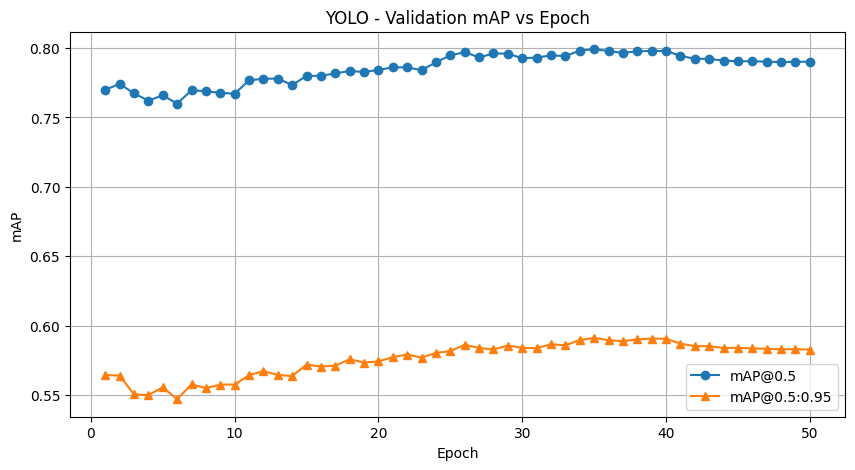

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("C:/content/drive/MyDrive/COLAB/A2/runs/yolo11n_full_finetune/results.csv")
df.columns = df.columns.str.strip()

plt.figure(figsize=(10, 5))

plt.plot(
    df["epoch"],
    df["metrics/mAP50(B)"],
    label="mAP@0.5",
    marker="o"
)

plt.plot(
    df["epoch"],
    df["metrics/mAP50-95(B)"],
    label="mAP@0.5:0.95",
    marker="^"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLO - Validation mAP vs Epoch")
plt.legend()
plt.grid()
plt.show()

In [80]:
import numpy as np

time_values = df["time"].dropna().to_numpy()
epoch_times = np.diff(time_values, prepend=0)

# resume then time reset
epoch_times[epoch_times < 0] = time_values[1:][epoch_times[1:] < 0]
total_time = epoch_times.sum()

print(f"Total training time: {total_time:.2f} seconds")
print(f"Total training time: {total_time / 60:.2f} minutes")
print(f"Total training time: {total_time / 3600:.2f} hours")

Total training time: 27103.27 seconds
Total training time: 451.72 minutes
Total training time: 7.53 hours
